![Banner](../images/03_05_banner_spatial_analysis_Network.png)



# Road networks with OSMnx: Routing and Accessibility



## Overview

[OSMnx](https://osmnx.readthedocs.io) downloads, models, and analyses street networks from
OpenStreetMap as NetworkX `MultiDiGraph`s with geometry. This notebook runs offline on the
synthetic GraphML in `Data/00_shared/data_spatial_net/` and uses
`geolattice.spatial_analysis.network_analysis` for travel times, snapping, routing summaries,
OD matrices, and closure impact.

Topics:

- Network statistics and edge speeds / travel times
- Snap towns to the network and route by distance vs time
- Town-to-town travel-time matrix
- Isochrones and cumulative-opportunity accessibility
- Critical segments and a road-closure scenario



## Getting real data from OpenStreetMap (reference)

The notebook runs offline on the synthetic network, but the code below is all you need to
repeat every step on a real place. The download functions return an unprojected graph
(lon/lat); project it before measuring areas or buffers.

```python
import osmnx as ox

# by place name (geocoded boundary)
G = ox.graph_from_place("Ithaca, New York, USA", network_type="drive")

# by point + distance, or by bounding box (left, bottom, right, top)
G = ox.graph_from_point((42.4440, -76.5019), dist=15_000, network_type="drive")
G = ox.graph_from_bbox((-76.60, 42.38, -76.40, 42.50), network_type="drive")

G = ox.project_graph(G)                # to the local UTM zone
ox.save_graphml(G, "ithaca_drive.graphml")

# points of interest (hospitals, schools, markets ...)
hospitals = ox.features_from_place(
    "Tompkins County, New York, USA", tags={"amenity": "hospital"}
)
```

`network_type` can be `"drive"`, `"walk"`, `"bike"`, `"all"`, or a custom Overpass filter.
Everything after Setup works identically on a downloaded graph.



## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`data/data_spatial_net`, and imports `geolattice.spatial_analysis.network_analysis` as `sna`.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / network / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for towns and study area
import matplotlib.pyplot as plt  # figure and axes creation for maps
import networkx as nx  # Dijkstra, ego graphs, and betweenness
import numpy as np  # numeric helpers used by later cells
import pandas as pd  # tabular display of stats and OD matrices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # hide library warnings in notebook output

# ===================================================================
# Setup for OSMnx routing demos.
# Import GeoLattice, point DATA at Data/00_shared/data_spatial_net,
# import network_analysis as sna, and load roads / towns / study area.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Synthetic road / town data used by the network chapter.
DATA = ROOT / "Data" / "00_shared" / "data_spatial_net"  # chapter sample-data folder under the repo

# Spatial network helpers (travel times, snapping, OD matrices).
from geolattice.spatial_analysis import network_analysis as sna  # spatial network helpers aliased as sna

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # compact figures with cleaner spines
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}  # notebook step
)
print("repo:", ROOT)  # status line for the notebook reader
print("data:", DATA)  # status line for the notebook reader
print("networkx", nx.__version__, "| geopandas", gpd.__version__)  # status line for the notebook reader

# OSMnx bridges NetworkX graphs and GeoDataFrames; Shapely builds isochrone polygons.
import osmnx as ox  # plot_graph, routing, and graph_to_gdfs
from shapely.geometry import Point, MultiPoint  # convex-hull inputs for isochrones
from shapely.ops import unary_union  # dissolve buffered reachable edges

# Load the offline road graph and place / boundary layers.
G = sna.load_road_graph(DATA / "roads.graphml")  # OSMnx-style MultiDiGraph
towns = gpd.read_file(DATA / "towns.geojson")  # routing origins / destinations
area = gpd.read_file(DATA / "study_area.geojson")  # polygon used for density stats
print(G, "| CRS:", G.graph["crs"])  # status line for the notebook reader



repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/00_shared/data_spatial_net
networkx 3.6.1 | geopandas 1.1.4


MultiDiGraph with 439 nodes and 1416 edges | CRS: EPSG:32618


## Part A: Network statistics

`ox.stats.basic_stats` returns the standard street-network descriptors. Passing the area lets it compute densities.



In [2]:
# ===================================================================
# Basic OSMnx street-network statistics, including density measures.
# Passing study-area size lets OSMnx compute per-km2 densities.
# ===================================================================

area_m2 = area.geometry.area.iloc[0]  # study-area area in square metres
stats = ox.stats.basic_stats(G, area=area_m2)  # standard street-network descriptors
# Keep a readable subset of the full stats dictionary.
keep = [  # boolean mask of hospitals that remain open
    "n", "m", "k_avg", "edge_length_total", "street_length_avg", "streets_per_node_avg",  # continue string literal
    "intersection_count", "intersection_density_km", "street_density_km", "circuity_avg",  # continue string literal
]
pd.Series({k: stats[k] for k in keep}).round(3).to_frame("value")  # run this analysis or plotting step



,value
n,439.000
m,1416.000
k_avg,6.451
edge_length_total,2926644.011
street_length_avg,2066.839
streets_per_node_avg,3.226
intersection_count,425.000
intersection_density_km,0.266
street_density_km,914.576
circuity_avg,1.016


## Part B: Speeds and travel times

Shortest *distance* is rarely what people care about; shortest *time* is. OSMnx imputes speeds in two steps:

1. `add_edge_speeds` reads the OSM `maxspeed` tag; where missing, it fills the mean observed speed of that `highway` class (or values you pass with `hwy_speeds`).
2. `add_edge_travel_times` computes `travel_time` (seconds) = length ÷ speed.



In [3]:
# ===================================================================
# Impute highway-class speeds and edge travel times (seconds).
# prepare_travel_times wraps OSMnx add_edge_speeds + add_edge_travel_times.
# ===================================================================

# Default speeds (km/h) by highway class when maxspeed tags are missing.
HWY_SPEEDS = {"residential": 50, "tertiary": 60, "secondary": 70, "primary": 90}  # default speeds (km/h) by highway class
# Attach speed_kph and travel_time attributes on every edge.
G = sna.prepare_travel_times(G, hwy_speeds=HWY_SPEEDS, minutes_attr=None)  # impute speeds and edge travel times
# Edge GeoDataFrame for grouped mean speed / length / time by class.
edges = ox.graph_to_gdfs(G, nodes=False)  # edge GeoDataFrame (LineStrings)
edges.groupby("highway")[["speed_kph", "length", "travel_time"]].mean().round(1)  # run this analysis or plotting step



,speed_kph,length,travel_time
highway,,,
primary,90.0,2026.9,81.1
residential,50.0,2039.5,146.8
secondary,70.0,2061.1,106.0
tertiary,60.0,2794.1,167.6


## Part C: Snapping places to the network and routing

Locations (towns, clinics, farms) rarely sit exactly on a network node. `ox.distance.nearest_nodes` snaps them using a spatial index. In a projected graph pass x/y in metres; in an unprojected graph pass lon/lat.



In [4]:
# ===================================================================
# Snap each town point to the nearest network node (spatial index).
# Routing uses these node ids rather than raw lon/lat coordinates.
# ===================================================================

towns["node"] = sna.snap_points_to_nodes(towns, G)  # nearest-node id per town
towns[["town", "population", "node"]].head()  # preview snapped ids



,town,population,node
0,Centerville,85000,220
1,Northfield,4880,227
2,Southport,7621,213
3,Eastbrook,12548,367
4,Westover,9215,73


In [5]:
# ===================================================================
# Compare shortest-distance vs fastest-time routes Riverton -> Ashford.
# The time-minimising path often detours onto higher-speed highways.
# ===================================================================

# Origin and destination node ids for the two towns.
o = towns.set_index("town").loc["Riverton", "node"]  # origin network node id
d = towns.set_index("town").loc["Ashford", "node"]  # destination network node id

# Shortest path by geometric length (metres).
route_len = ox.routing.shortest_path(G, o, d, weight="length")  # shortest path by geometric length
# Shortest path by travel time (seconds).
route_tt = ox.routing.shortest_path(G, o, d, weight="travel_time")  # shortest path by travel time

# Side-by-side summary of distance, time, and related route stats.
pd.DataFrame({  # run this analysis or plotting step
    "shortest distance": sna.route_summary(G, route_len),  # call a geolattice.network_analysis helper
    "fastest time": sna.route_summary(G, route_tt),  # call a geolattice.network_analysis helper
}).T.round(1)  # run this analysis or plotting step



,km,minutes,segments,% on primary/secondary
shortest distance,52.3,57.7,27.0,17.4
fastest time,56.8,47.5,27.0,75.7


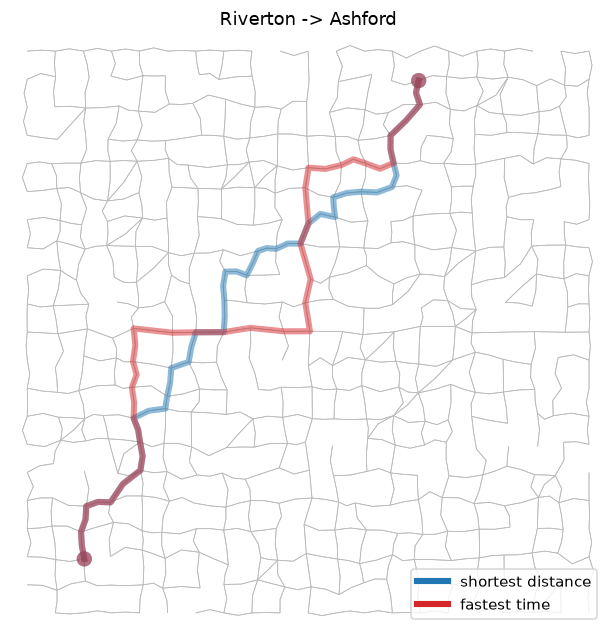

In [6]:
# ===================================================================
# Plot both Riverton-Ashford routes on the road graph.
# Blue = shortest distance; red = fastest travel time.
# ===================================================================

fig, ax = ox.plot.plot_graph_routes(  # OSMnx plot / routing call
    G,  # notebook step
    [route_len, route_tt],  # both node sequences
    route_colors=["#1f77b4", "#d62728"],  # distance vs time colours
    route_linewidths=4,  # stroke widths for overlaid routes
    node_size=0,  # hide junction markers for clarity
    edge_color="#bbbbbb",  # NetworkX / OSMnx edge colour
    edge_linewidth=0.5,  # road / edge stroke width
    bgcolor="white",  # map background colour
    show=False,  # return axes for a custom legend
    close=False,  # keep the figure open for further editing
    figsize=(7, 7),  # figure width x height in inches
)
# Manual legend matching the two route colours.
ax.legend(  # add a legend for mapped layers
    handles=[  # handles argument
        plt.Line2D([], [], color="#1f77b4", lw=4, label="shortest distance"),  # continue multi-line call
        plt.Line2D([], [], color="#d62728", lw=4, label="fastest time"),  # continue multi-line call
    ],
    loc="lower right",  # legend location
)
ax.set_title("Riverton -> Ashford")  # panel / map title
plt.show()  # render the figure in the notebook



The fastest route detours onto the highways: a few extra kilometres buy a substantial time saving. This is exactly why distance-based accessibility measures underestimate the advantage of places near major roads.

### Travel-time matrix between towns

For many origin-destination pairs, run one Dijkstra per origin rather than one shortest path per pair.



In [7]:
# ===================================================================
# Town-to-town OD travel-time matrix (minutes).
# One Dijkstra per origin is faster than a shortest path per pair.
# ===================================================================

TT = sna.od_travel_time_matrix(  # town-to-town travel-time matrix
    G,  # notebook step
    towns,  # origins/destinations with a snapped node column
    node_col="node",  # column holding network node ids
    id_col="town",  # row/column labels in the matrix
    weight="travel_time",  # impedance attribute on edges
    unit="minutes",  # convert seconds to minutes for display
)
TT.round(1)  # run this analysis or plotting step



,Centerville,Northfield,Southport,Eastbrook,Westover,Maple Falls,Cedar Ridge,Pine Hollow,Oak Grove,Willow Creek,Brookside,Fairview,Hillcrest,Lakeview,Riverton,Stonebridge,Elmwood,Ashford,Granville,Millbrook
Centerville,0.0,9.5,9.3,9.6,9.5,18.3,18.6,18.5,18.3,9.1,9.3,8.8,8.0,26.1,26.5,26.3,26.6,21.0,19.2,20.5
Northfield,9.5,0.0,18.8,19.0,19.0,12.2,12.2,28.0,27.8,14.9,18.8,18.3,9.0,20.3,36.0,35.7,20.2,12.4,26.4,30.0
Southport,9.3,18.8,0.0,18.9,18.8,27.6,27.9,12.9,11.6,18.4,14.9,9.8,17.3,35.4,20.1,19.6,35.9,30.3,28.5,23.3
Eastbrook,9.6,19.0,18.9,0.0,19.1,12.7,28.2,28.1,13.9,11.5,18.9,13.2,17.6,20.5,36.1,20.7,36.2,22.8,10.1,30.1
Westover,9.5,19.0,18.8,19.1,0.0,27.9,12.9,12.3,27.8,18.6,10.6,18.3,14.7,35.6,19.2,35.8,19.6,30.5,28.7,11.3
Maple Falls,18.3,12.2,27.6,12.7,27.9,0.0,21.4,36.9,23.0,12.4,27.7,22.3,18.2,11.5,44.9,29.8,29.4,11.9,16.8,38.9
Cedar Ridge,18.6,12.2,27.9,28.2,12.9,21.4,0.0,22.9,36.9,24.1,20.1,27.4,13.5,29.5,29.9,44.8,12.3,23.7,35.6,23.9
Pine Hollow,18.5,28.0,12.9,28.1,12.3,36.9,22.9,0.0,21.9,27.6,11.7,19.7,23.8,44.6,11.6,29.8,29.6,39.5,37.7,12.1
Oak Grove,18.3,27.8,11.6,13.9,27.8,23.0,36.9,21.9,0.0,21.8,23.9,11.5,26.3,30.8,29.1,11.9,44.9,33.1,23.9,32.3
Willow Creek,9.1,14.9,18.4,11.5,18.6,12.4,24.1,27.6,21.8,0.0,18.4,13.9,13.5,21.0,35.6,28.6,32.1,21.1,18.3,29.6


Save this matrix: 03.06.5 uses town-to-town travel times to fit a gravity model of commuting.



In [8]:
# ===================================================================
# Persist the town travel-time matrix for the gravity model notebook.
# 03.06.5 reads town_travel_time_min.csv as impedance input.
# ===================================================================

TT.to_csv(DATA / "town_travel_time_min.csv")  # minutes, town x town



## Part D: Isochrones

An **isochrone** is the area reachable within a time budget. Two steps:

1. `nx.ego_graph(G, center, radius=t, distance="travel_time")` returns every node reachable within *t*.
2. Turn the reachable network into a polygon. A **convex hull** is fast but overstates coverage; buffering the reachable edges and dissolving them is more faithful to the network.



In [9]:
# ===================================================================
# Build nested isochrones from Centerville for 8 / 15 / 22 minute budgets.
# Compare convex-hull area with a network-buffer polygon area.
# ===================================================================

center = towns.set_index("town").loc["Centerville", "node"]  # isochrone seed node
budgets = [8, 15, 22]  # minutes
colors = ["#fee391", "#fe9929", "#cc4c02"]  # light -> dark for increasing time
iso = []  # accumulate one record per time budget
# Draw largest budget first so smaller fills sit on top in the map cell.
for t in sorted(budgets, reverse=True):  # iterate over the collection
    # Nodes reachable within t minutes (radius is in seconds).
    sub = nx.ego_graph(G, center, radius=t * 60, distance="travel_time")  # sub argument
    e = ox.graph_to_gdfs(sub, nodes=False)  # reachable edge geometries
    # Fast but optimistic coverage: convex hull of reachable nodes.
    hull = MultiPoint([Point(G.nodes[n]["x"], G.nodes[n]["y"]) for n in sub.nodes]).convex_hull  # hull argument
    # Network-faithful outline: buffer edges, dissolve, then erode slightly.
    buff = unary_union(e.geometry.buffer(1500)).buffer(-700)  # dilate then erode = smoother outline
    iso.append({  # append this record
        "minutes": t,  # continue string literal
        "nodes": sub.number_of_nodes(),  # continue multi-line call
        "hull_km2": hull.area / 1e6,  # continue string literal
        "network_km2": buff.area / 1e6,  # continue string literal
        "geometry": buff,  # continue string literal
        "hull": hull,  # continue string literal
    })
iso = gpd.GeoDataFrame(iso, crs=G.graph["crs"])  # isochrone records / GeoDataFrame
iso[["minutes", "nodes", "hull_km2", "network_km2"]].round(1)  # run this analysis or plotting step



,minutes,nodes,hull_km2,network_km2
0,22,322,1241.4,1249.0
1,15,177,811.7,666.1
2,8,49,229.9,172.3


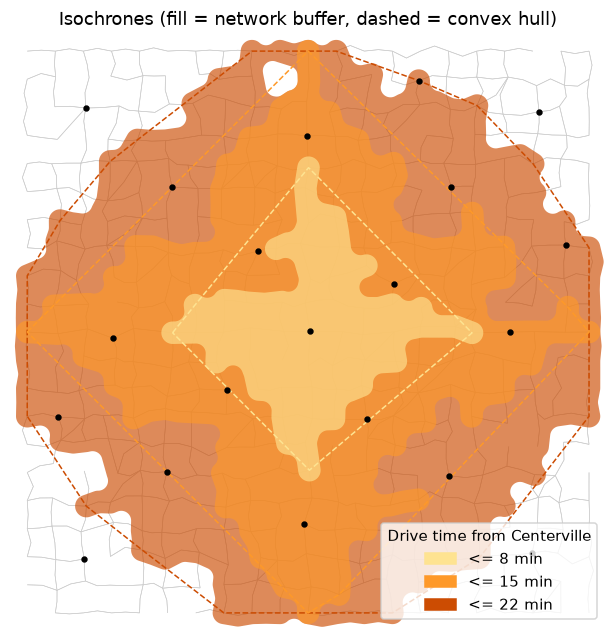

In [10]:
# ===================================================================
# Map network-buffer isochrones (fill) and convex hulls (dashed).
# Hulls overstate coverage in the gaps between highway corridors.
# ===================================================================

fig, ax = ox.plot.plot_graph(  # OSMnx plot / routing call
    G,  # notebook step
    node_size=0,  # hide or size junction markers
    edge_color="#cccccc",  # NetworkX / OSMnx edge colour
    edge_linewidth=0.4,  # road / edge stroke width
    bgcolor="white",  # map background colour
    show=False,  # defer or trigger OSMnx's own display
    close=False,  # keep the figure open for further editing
    figsize=(7, 7),  # figure width x height in inches
)
# Plot fills from largest to smallest; dashed outline is the convex hull.
for r, c in zip(iso.itertuples(), colors[::-1]):  # iterate paired sequences together
    gpd.GeoSeries([r.geometry]).plot(ax=ax, color=c, alpha=0.65, zorder=1)  # draw geometries or a series on the axes
    gpd.GeoSeries([r.hull]).boundary.plot(ax=ax, color=c, linestyle="--", lw=1)  # draw geometries or a series on the axes
towns.plot(ax=ax, color="k", markersize=10, zorder=3)  # town markers for reference
ax.legend(  # add a legend for mapped layers
    handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f"<= {t} min") for t, c in zip(budgets, colors)],  # handles argument
    loc="lower right",  # legend location
    title="Drive time from Centerville",  # plot or map title
)
ax.set_title("Isochrones (fill = network buffer, dashed = convex hull)")  # panel / map title
plt.show()  # render the figure in the notebook



Isochrones stretch along the highways into star shapes. The dashed convex hulls overstate coverage in the gaps between corridors, which matters when the isochrone is used to count people "within 20 minutes" of a service (03.06.4).

## Part E: Accessibility surface

**Cumulative-opportunity accessibility** counts the opportunities (here, town population as a proxy for jobs and services) reachable within a time threshold:

$$A_i = \sum_j O_j \cdot \mathbb{1}(t_{ij} \le T)$$

Computing it for every node gives a continuous accessibility surface.



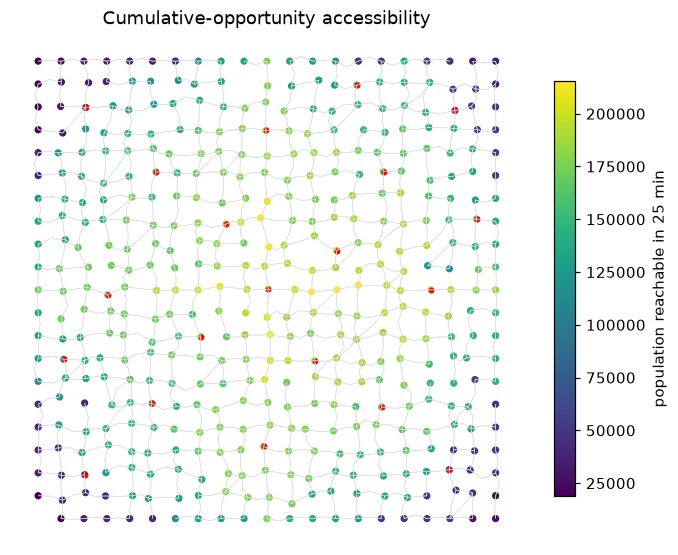

In [11]:
# ===================================================================
# Cumulative-opportunity accessibility within 25 minutes of each node.
# Opportunity proxy: town population snapped onto network nodes.
# ===================================================================

T = 25 * 60  # accessibility time budget in seconds
# Population mass at each snapped town node (sum if duplicates share a node).
town_nodes = towns.set_index("node")["population"].groupby(level=0).sum()  # population mass at snapped town nodes
acc = {}  # node id -> reachable population
for n in G.nodes:  # iterate over the collection
    # All nodes reachable from n within the time cutoff.
    reach = nx.single_source_dijkstra_path_length(G, n, cutoff=T, weight="travel_time")  # reach argument
    acc[n] = town_nodes.reindex(list(reach)).sum()  # sum population at reached town nodes
nodes = ox.graph_to_gdfs(G, edges=False)  # node GeoDataFrame (Points)
nodes["access_25min"] = pd.Series(acc)  # attach accessibility to the node gdf

fig, ax = plt.subplots(figsize=(7.5, 7))  # create figure and primary axes
ox.graph_to_gdfs(G, nodes=False).plot(ax=ax, color="#dddddd", lw=0.4)  # faint road backdrop
nodes.sort_values("access_25min").plot(  # draw geometries or a series on the axes
    ax=ax,  # draw into these axes
    column="access_25min",  # attribute used for the choropleth
    cmap="viridis",  # colormap for continuous / categorical values
    markersize=14,  # marker area or size
    legend=True,  # show a legend or colour bar
    legend_kwds={"label": "population reachable in 25 min", "shrink": 0.7},  # legend / colour-bar styling
)
towns.plot(ax=ax, color="red", markersize=8)  # opportunity locations
ax.set_title("Cumulative-opportunity accessibility")  # panel / map title
ax.set_axis_off()  # hide coordinate ticks for a clean map
plt.show()  # render the figure in the notebook



## Part F: Critical segments and a road closure

**Edge betweenness** weighted by travel time estimates how many fastest paths use each segment; high values mark corridors whose disruption would affect many trips. On large graphs use `k` sampled sources for speed.



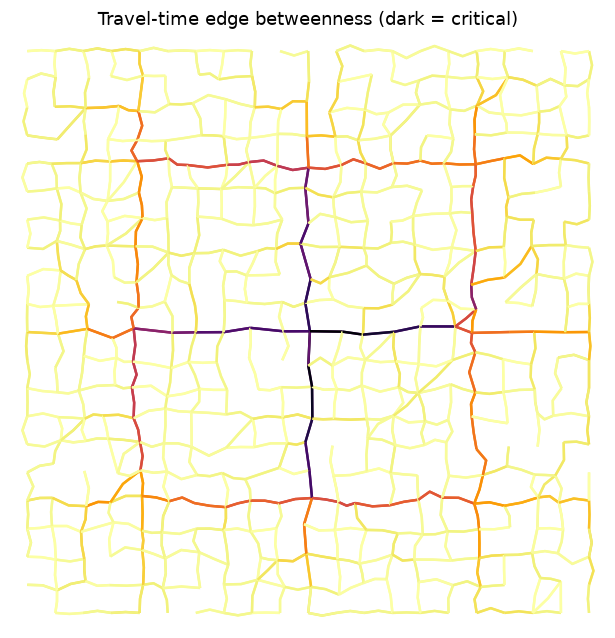

,,,highway,length,travel_time,betweenness
u,v,key,,,,
241,220,0,primary,2327.427,93.097,0.122
262,241,0,primary,1464.093,58.564,0.121
220,219,0,primary,2464.487,98.579,0.120
219,218,0,primary,1516.897,60.676,0.119
218,217,0,primary,2271.351,90.854,0.115
283,262,0,primary,2227.121,89.085,0.113
217,216,0,primary,1737.366,69.495,0.107
304,283,0,primary,1905.703,76.228,0.106
221,220,0,primary,2047.442,81.898,0.104


In [12]:
# ===================================================================
# Travel-time edge betweenness (sampled) to flag critical corridors.
# High values mark segments that lie on many fastest paths.
# ===================================================================

Gd = nx.DiGraph(G)  # collapse parallel edges for betweenness
# Sample k=200 sources for speed on this regional graph.
eb = nx.edge_betweenness_centrality(Gd, k=200, weight="travel_time", seed=42)  # edge betweenness scores
# Store betweenness on key=0 edges of the original MultiDiGraph.
nx.set_edge_attributes(G, {(u, v, 0): b for (u, v), b in eb.items()}, "betweenness")  # run this analysis or plotting step
ec = ox.plot.get_edge_colors_by_attr(G, "betweenness", cmap="inferno_r")  # edge colours scaled by betweenness
fig, ax = ox.plot.plot_graph(  # OSMnx plot / routing call
    G,  # notebook step
    node_size=0,  # hide or size junction markers
    edge_color=ec,  # NetworkX / OSMnx edge colour
    edge_linewidth=1.6,  # road / edge stroke width
    bgcolor="white",  # map background colour
    show=False,  # defer or trigger OSMnx's own display
    close=False,  # keep the figure open for further editing
    figsize=(7, 7),  # figure width x height in inches
)
ax.set_title("Travel-time edge betweenness (dark = critical)")  # panel / map title
plt.show()  # render the figure in the notebook

# Rank edges and preview the ten most critical segments.
edges = ox.graph_to_gdfs(G, nodes=False)  # edge GeoDataFrame (LineStrings)
top = edges.sort_values("betweenness", ascending=False).head(10)  # highest-betweenness road segments
top[["highway", "length", "travel_time", "betweenness"]].round(3)  # run this analysis or plotting step



Now close the single most critical segment (both directions) and measure the impact on travel times between all towns.



In [13]:
# ===================================================================
# Close the single most critical segment (both directions) and measure
# the change in town-to-town travel times versus the baseline matrix TT.
# ===================================================================

u, v, _ = top.index[0]  # endpoints of the highest-betweenness edge
G_closed = G.copy()  # road graph with the critical segment removed
G_closed.remove_edges_from([(u, v, 0), (v, u, 0)])  # remove both directions

# Minute-level delay matrix relative to the open-network baseline.
delta = sna.od_travel_time_matrix(  # change in travel times after the closure
    G_closed,  # notebook step
    towns,  # notebook step
    node_col="node",  # column holding snapped network node ids
    id_col="town",  # row/column labels for the OD matrix
    weight="travel_time",  # edge impedance attribute for path search
    unit="minutes",  # convert travel times to this display unit
) - TT
print(f"Closed segment {u}-{v} ({top.iloc[0].highway})")  # status line for the notebook reader
print(f"Town pairs affected: {(delta > 0.05).values.sum()} of {delta.size - len(delta)}")  # status line for the notebook reader
print(  # status line for the notebook reader
    f"Largest delay: {delta.values.max():.1f} min; "  # run this analysis or plotting step
    f"mean delay among affected pairs: {delta[delta > 0.05].stack().mean():.1f} min"  # run this analysis or plotting step
)
# Worst added minutes from each origin town (top 5).
delta.max(axis=1).sort_values(ascending=False).head(5).round(1).to_frame(  # continue multi-line call
    "worst added minutes from town"  # continue string literal
)



Closed segment 241-220 (primary)
Town pairs affected: 80 of 380
Largest delay: 5.6 min; mean delay among affected pairs: 2.4 min


,worst added minutes from town
Eastbrook,5.6
Westover,5.6
Brookside,5.6
Centerville,5.6
Millbrook,5.6


Thanks to the grid's redundancy no town is cut off, but trips through the regional center slow down. In a sparser rural network or a river valley with few bridges, the same analysis identifies single points of failure: a direct input to emergency planning.

## Summary

- `graph_from_place / point / bbox` → `project_graph` → `save_graphml` is the standard OSMnx data pipeline.
- `add_edge_speeds` + `add_edge_travel_times` turn a geometric network into a **time** network.
- `nearest_nodes` snaps places to the network; `shortest_path` and Dijkstra give routes and OD matrices.
- Isochrones = `ego_graph` with a travel-time radius, then a polygon (prefer network buffers to convex hulls).
- Cumulative accessibility and travel-time betweenness reveal who is well connected and which roads matter most.

### Exercises

1. Reduce all residential speeds to 30 km/h (a snowstorm) and recompute the 25-minute accessibility surface. Which towns lose the most?
2. Replace the cumulative measure with a **gravity accessibility** $A_i = \sum_j O_j e^{-\beta t_{ij}}$ and compare maps for β = 0.05 and 0.15.
3. Close the five highest-betweenness segments at once. Does any town pair now exceed 60 minutes?
4. Download a real `drive` network for your own county and reproduce Parts B-D.

**Next:** 03.06.3 builds networks directly from polygons and points with GeoPandas and libpysal.

